# Mission 06 - The Autonomous Warp State Machine & Deliberation Loop
Squadron Fei-Fei (Group 13), Conversational AI, BTU WS 2026/27. Sector SEC-06-CAR (Eta Carinae).

Each station's code lives in its numbered script; this notebook imports and runs them, then ends with the four `assert` test suites required by the brief. Standard library only, apart from matplotlib for one plot.

In [1]:
import sys, platform
from IPython.display import Image, display
from common import load_part
import nebula
core = load_part('01_Agent_State_Machine.py')
protocol = load_part('02_Tool_Protocol_Dispatcher.py')
mdp = load_part('03_MDP_Trajectory_Logger.py')
guard = load_part('04_Infinite_Loop_Sentinel.py')
pilot = load_part('05_System2_Warp_Pilot.py')
print(sys.version.split()[0], '|', platform.platform())

3.12.16 | macOS-26.4.1-x86_64-i386-64bit


## Part 1 - Systems Architect: agent state machine
`AgentState` enum with the seven required states, `@dataclass Agent`, and `step()` executing exactly one transition of IDLE -> PERCEIVING -> DELIBERATING -> ACTING -> OBSERVING -> REFLECTING -> (DELIBERATING | HALTED). The budget is at most 20 steps; the next call forces HALTED.

In [2]:
core.main()

=== Part 1: Deterministic cycle with a 20-step budget (never completes) ===
call 01:         IDLE -> PERCEIVING
call 02:   PERCEIVING -> DELIBERATING
call 03: DELIBERATING -> ACTING
call 04:       ACTING -> OBSERVING
call 05:    OBSERVING -> REFLECTING
call 06:   REFLECTING -> DELIBERATING
call 07: DELIBERATING -> ACTING
call 08:       ACTING -> OBSERVING
call 09:    OBSERVING -> REFLECTING
call 10:   REFLECTING -> DELIBERATING
call 11: DELIBERATING -> ACTING
call 12:       ACTING -> OBSERVING
call 13:    OBSERVING -> REFLECTING
call 14:   REFLECTING -> DELIBERATING
call 15: DELIBERATING -> ACTING
call 16:       ACTING -> OBSERVING
call 17:    OBSERVING -> REFLECTING
call 18:   REFLECTING -> DELIBERATING
call 19: DELIBERATING -> ACTING
call 20:       ACTING -> OBSERVING
call 21:    OBSERVING -> HALTED
step_count=20, state=HALTED, reason='step budget of 20 exhausted'

=== Part 1: Mission completes on the first reflection ===
IDLE -> PERCEIVING -> DELIBERATING -> ACTING -> OBSERVING -> R

## Part 2 - Protocol Officer: tool protocol and action dispatcher
Three tools, JSON-Schema contracts checked by a validator written here, and an exception boundary that turns every failure into an observation `Tool Execution Error: <msg>`.

In [3]:
protocol.main()

=== Part 2: Dispatcher contract and error boundary ===
> {"tool": "query_sensor_array", "arguments": {"target": "escape_corridor"}}
  Observation: Clear gravitational corridor detected along vector [-0.85, 0.52, 0.05].
> {"tool": "adjust_plasma_shields", "arguments": {"intensity": 85}}
  Observation: Plasma shield harmonics adjusted to 85% capacity.
> {"tool": "adjust_plasma_shields", "arguments": {"intensity": -20}}
  Tool Execution Error: ValueError: shield intensity -20% is out of bounds; valid range is [0, 100]
> {"tool": "adjust_plasma_shields", "arguments": {"intensity": true}}
  Tool Execution Error: adjust_plasma_shields contract violation: arguments.intensity must be of type integer, got bool
> {"tool": "navigate_warp_vector", "arguments": {"x": -0.85, "y": 0.52}}
  Tool Execution Error: navigate_warp_vector contract violation: missing required argument 'z'
> {"tool": "navigate_warp_vector", "arguments": {"x": 3, "y": 0, "z": 0}}
  Tool Execution Error: navigate_warp_vector co

## Part 3 - Data & Payload Specialist: MDP trajectory logger and discounted return
tau = (s_0, a_0, r_0, ..., s_T), G_0 = sum gamma^t r_t with gamma = 0.95, and the empirical P(s'|s,a) from 600 synthetic historical jumps (`data/historical_jumps.csv`). Bellman value iteration on the estimated model gives the Q-values that System 2 uses for lookahead.

In [4]:
mdp.main()

=== Part 3: Discounted return of the brief's trajectory ===
tau = ['s0', 'a0', 10.0, 's1', 'a1', 0.0, 's2', 'a2', -5.0, 's3', 'a3', 20.0, 's4']
G_0 = 10 + 0.95*0 + 0.95^2*(-5) + 0.95^3*20 = 22.635
G_t = [22.635, 13.3, 14.0, 20.0]

=== Part 3: Empirical P(s'|s,a) from 600 synthetic historical jumps ===
     CORE | CORRIDOR | n= 68 | CORE=0.294, CORRIDOR=0.706
     CORE | DIRECT   | n= 77 | CORE=0.506, OPEN_SPACE=0.494
 CORRIDOR | CORRIDOR | n= 80 | CORRIDOR=0.037, OPEN_SPACE=0.963
 CORRIDOR | DIRECT   | n= 73 | CORRIDOR=0.068, OPEN_SPACE=0.932
DUST_LANE | CORRIDOR | n= 77 | CORRIDOR=0.896, DUST_LANE=0.104
DUST_LANE | DIRECT   | n= 72 | DUST_LANE=1.000
     LOBE | CORRIDOR | n= 74 | CORRIDOR=0.878, DUST_LANE=0.122
     LOBE | DIRECT   | n= 79 | CORE=0.835, DUST_LANE=0.165
Max |P_hat - P_true| = 0.035

=== Part 3: Bellman value iteration on the estimated model (gamma = 0.95) ===
     LOBE | V*=  92.07 | Q(DIRECT)=  87.37 | Q(CORRIDOR)=  92.07
DUST_LANE | V*=  92.18 | Q(DIRECT)=  82.57 | Q

## Part 4 - Security Sentinel: cycle detection and halting guardrail (Ship Anomaly 06)
SHA-256 hashes of (environment state, planned action, arguments); a hash table gives O(1) repeat counts and Floyd's tortoise-and-hare finds cycles online. The emergency tripwire forces HALTED and logs a CRITICAL violation.

In [5]:
guard.main()

=== Part 4: Floyd on a periodic state-action trace [s1, s2, s3, s1, s2, s3, ...] ===
Elements processed: 7 of 18
Agent: state=HALTED, step_count=7, reason='EMERGENCY TRIPWIRE: Floyd cycle detected: mu=0, lambda=3, tortoise=3, hare=6'
Security log: {"level": "CRITICAL", "event": "EMERGENCY_TRIPWIRE", "step": 6, "reason": "Floyd cycle detected: mu=0, lambda=3, tortoise=3, hare=6", "action": "scan", "arguments": {}, "hash": "9afd6cbe9e812f5b", "repeats": 3}

=== Part 4: Same failed action in the same state (O(1) hash counter) ===
attempt 1: hash fa51dd5f0689a129... failures=1 tripwire=armed
attempt 2: hash fa51dd5f0689a129... failures=2 tripwire=armed
attempt 3: hash fa51dd5f0689a129... failures=3 tripwire=FIRED - same failed action in the same state 3 times

=== Part 4: Floyd (mu, lambda) on sample sequences ===
abcabcabc    -> (0, 3)
xyabababab   -> (2, 2)
aaaa         -> (0, 1)
abcdefgh     -> None
[PASS] Loop sentinel verified.


## Integration - System 1 reflex vs System 2 deliberation
Every episode is driven by the Part 1 state machine; actions go through the Part 2 dispatcher, rewards into the Part 3 logger and every plan past the Part 4 sentinel.

=== Ship Anomaly 06: AURA trapped in the dust lane (start DUST_LANE, shields 30%) ===

--- Dust lane: System 1 (reflex) ---
  step  4 | DUST_LANE shields  30% | reflex: shortest heading to open space
          {"tool": "navigate_warp_vector", "arguments": {"x": 1.0, "y": 0.0, "z": 0.0}}
          -> Tool Execution Error: ValueError: gravitational shear wall blocks the DIRECT heading from DUST_LANE; jump aborted  [r=-5.0]
  step  8 | DUST_LANE shields  30% | reflex: shortest heading to open space
          {"tool": "navigate_warp_vector", "arguments": {"x": 1.0, "y": 0.0, "z": 0.0}}
          -> Tool Execution Error: ValueError: gravitational shear wall blocks the DIRECT heading from DUST_LANE; jump aborted  [r=-5.0]
  step 10 | TRIPWIRE: Floyd cycle detected: mu=0, lambda=1, tortoise=1, hare=2
  outcome=tripwire | final=DUST_LANE | agent steps=10 | G0=-9.75 | halt='EMERGENCY TRIPWIRE: Floyd cycle detected: mu=0, lambda=1, tortoise=1, hare=2'

--- Dust lane: System 2 (deliberative) ---


Pilot                    | escaped | breach | tripwire | budget |  mean G0 | steps | errors
System 1 (reflex)        |   35.9% |  44.0% |    19.2% |   0.9% |   -10.43 | 10.96 |   0.19
System 2 (deliberative)  |   99.9% |   0.0% |     0.0% |   0.1% |    91.78 | 10.84 |   0.00


Saved evidence/pilot_results.json, episode_traces.json, security_log.jsonl, pilot_comparison.png


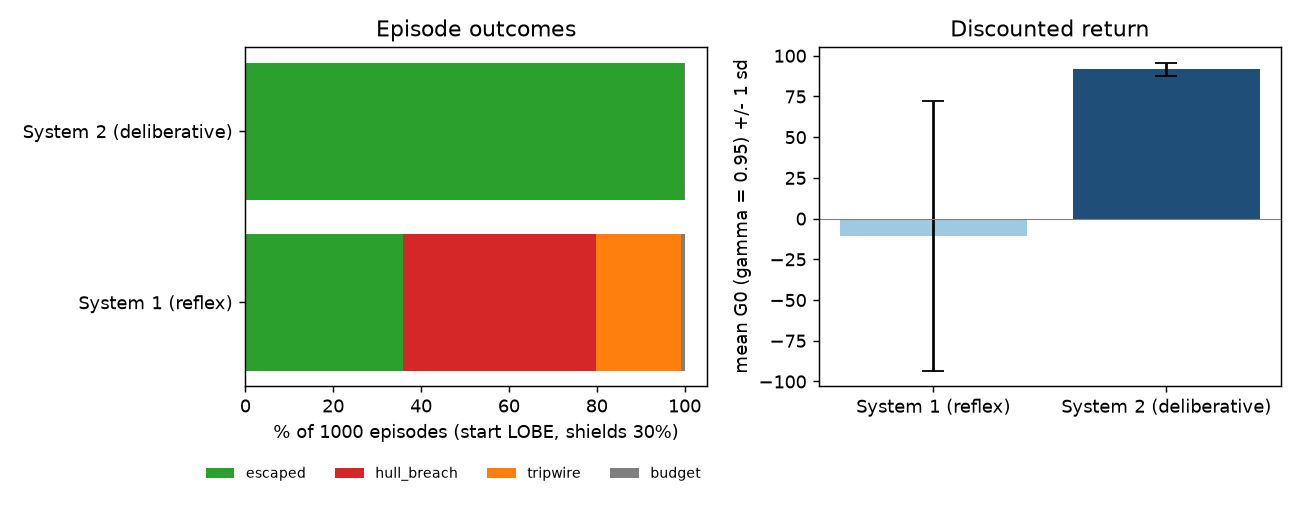

In [6]:
pilot.main()
display(Image('evidence/pilot_comparison.png'))

## Master test suite (brief section 3)

In [7]:
# 1. State machine test: IDLE ... HALTED, and strict termination when forced to run 21 steps
agent = core.Agent()
assert agent.state is core.AgentState.IDLE
core.run_until_halt(agent, 5)
assert agent.state is core.AgentState.REFLECTING
agent.mission_completed = True
assert agent.step() is core.AgentState.HALTED
forced = core.Agent(max_steps=20)
for _ in range(21):
    forced.step()
assert forced.state is core.AgentState.HALTED and forced.step_count == 20
print('State machine test passed:', forced.halt_reason)

State machine test passed: step budget of 20 exhausted


In [8]:
# 2. Protocol dispatch test: invalid JSON returns an error observation and does not crash
d = protocol.ActionDispatcher(protocol.ShipTools(nebula.NebulaEnvironment()))
obs = d.dispatch('{"tool": "adjust_plasma_shields", "arguments": {"intensity": 70}')
assert isinstance(obs, str) and obs.startswith('Tool Execution Error: ')
obs2 = d.dispatch({'tool': 'adjust_plasma_shields', 'arguments': {'intensity': -10}})
assert obs2.startswith('Tool Execution Error: ValueError')
print('Protocol dispatch test passed:', obs)

Protocol dispatch test passed: Tool Execution Error: invalid JSON payload (Expecting ',' delimiter at character 64)


In [9]:
# 3. MDP return test: rewards [10, 0, -5, 20], gamma = 0.95
g0 = mdp.discounted_return([10, 0, -5, 20], gamma=0.95)
expected = 10 + 0.95 * 0 + 0.95**2 * (-5) + 0.95**3 * 20
assert abs(g0 - expected) < 1e-12 and abs(g0 - 22.635) < 1e-9
print('MDP return test passed: G0 =', round(g0, 6))

MDP return test passed: G0 = 22.635


In [10]:
# 4. Sentinel cycle test: [s1, s2, s3, s1, s2, s3, ...] must be detected and halted before step 10
mock = [('s1', 'a1'), ('s2', 'a2'), ('s3', 'a3')] * 5
result = guard.guarded_replay(mock)
assert result['agent'].state is core.AgentState.HALTED
assert result['processed'] < 10 and result['agent'].step_count < 10
print('Sentinel cycle test passed at element', result['processed'], '-', result['agent'].halt_reason)

Sentinel cycle test passed at element 7 - EMERGENCY TRIPWIRE: Floyd cycle detected: mu=0, lambda=3, tortoise=3, hare=6


In [11]:
import subprocess
r = subprocess.run([sys.executable, '-m', 'unittest', 'test_ps06.py'], capture_output=True, text=True)
print(r.stderr.strip().splitlines()[-3], '|', r.stderr.strip().splitlines()[-1])

Ran 19 tests in 0.010s | OK


## Squadron sign-off
Each officer ticks their own box after reviewing their part.

- [ ] Systems Architect: Bilal Younus
- [ ] Communications & Protocol Officer: Danish Hafeez
- [ ] Data & Payload Specialist: Anas Arshad
- [ ] Security & Ethics Sentinel: Shahzaib Ahmed